In [ ]:
import os

print(os.listdir('/content'))

['.config', 'archive (2).zip', 'sample_data']


In [ ]:
import zipfile
import os

zip_path = '/content/archive (2).zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/extracted_data')

print("ZIP file extracted successfully!")

print(os.listdir('/content/extracted_data'))

ZIP file extracted successfully!
['data.csv']


In [ ]:
import os

print(os.listdir('/content/extracted_data'))

['data.csv']


In [ ]:
import pandas as pd

df = pd.read_csv(
    '/content/extracted_data/data.csv',
    encoding='latin1'
)

print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [ ]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [ ]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [ ]:
print("Missing values in each column:")

print(df.isnull().sum())

Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 5268


In [ ]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [ ]:
print(df.columns.tolist())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [ ]:
print("Total records:", df.shape[0])
print("Total columns:", df.shape[1])

Total records: 541909
Total columns: 8


In [ ]:
df.dtypes

,0
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,object
UnitPrice,float64
CustomerID,float64
Country,object


In [ ]:
print(df.columns.tolist())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [ ]:
# Calculate total sales
df['Sales'] = df['Quantity'] * df['UnitPrice']

total_sales = df['Sales'].sum()

print("Total Sales: £", round(total_sales, 2))

Total Sales: £ 9747747.93


In [ ]:
total_orders = df['InvoiceNo'].nunique()

print("Total Orders:", total_orders)

Total Orders: 25900


In [ ]:
top_products = (
    df.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     53847
JUMBO BAG RED RETROSPOT               47363
ASSORTED COLOUR BIRD ORNAMENT         36381
POPCORN HOLDER                        36334
PACK OF 72 RETROSPOT CAKE CASES       36039
WHITE HANGING HEART T-LIGHT HOLDER    35317
RABBIT NIGHT LIGHT                    30680
MINI PAINT SET VINTAGE                26437
PACK OF 12 LONDON TISSUES             26315
PACK OF 60 PINK PAISLEY CAKE CASES    24753
Name: Quantity, dtype: int64


In [ ]:
top_products = (
    df.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     53847
JUMBO BAG RED RETROSPOT               47363
ASSORTED COLOUR BIRD ORNAMENT         36381
POPCORN HOLDER                        36334
PACK OF 72 RETROSPOT CAKE CASES       36039
WHITE HANGING HEART T-LIGHT HOLDER    35317
RABBIT NIGHT LIGHT                    30680
MINI PAINT SET VINTAGE                26437
PACK OF 12 LONDON TISSUES             26315
PACK OF 60 PINK PAISLEY CAKE CASES    24753
Name: Quantity, dtype: int64


In [ ]:
country_sales = (
    df.groupby('Country')['Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(country_sales)

Country
United Kingdom    8187806.364
Netherlands        284661.540
EIRE               263276.820
Germany            221698.210
France             197403.900
Australia          137077.270
Switzerland         56385.350
Spain               54774.580
Belgium             40910.960
Sweden              36595.910
Name: Sales, dtype: float64


In [ ]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

df['Month'] = df['InvoiceDate'].dt.to_period('M')

monthly_sales = df.groupby('Month')['Sales'].sum()

print(monthly_sales)

Month
2010-12     748957.020
2011-01     560000.260
2011-02     498062.650
2011-03     683267.080
2011-04     493207.121
2011-05     723333.510
2011-06     691123.120
2011-07     681300.111
2011-08     682680.510
2011-09    1019687.622
2011-10    1070704.670
2011-11    1461756.250
2011-12     433668.010
Freq: M, Name: Sales, dtype: float64


In [ ]:
total_orders = df['InvoiceNo'].nunique()

print("Total Orders:", total_orders)

Total Orders: 25900


In [ ]:
total_customers = df['CustomerID'].nunique()

print("Total Unique Customers:", total_customers)


Total Unique Customers: 4372


In [ ]:
top_products = (
    df.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Quantity Sold:")
print(top_products)

Top 10 Products by Quantity Sold:
Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     53847
JUMBO BAG RED RETROSPOT               47363
ASSORTED COLOUR BIRD ORNAMENT         36381
POPCORN HOLDER                        36334
PACK OF 72 RETROSPOT CAKE CASES       36039
WHITE HANGING HEART T-LIGHT HOLDER    35317
RABBIT NIGHT LIGHT                    30680
MINI PAINT SET VINTAGE                26437
PACK OF 12 LONDON TISSUES             26315
PACK OF 60 PINK PAISLEY CAKE CASES    24753
Name: Quantity, dtype: int64


In [ ]:
country_sales = (
    df.groupby('Country')['Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Countries by Sales:")
print(country_sales)

Top 10 Countries by Sales:
Country
United Kingdom    8187806.364
Netherlands        284661.540
EIRE               263276.820
Germany            221698.210
France             197403.900
Australia          137077.270
Switzerland         56385.350
Spain               54774.580
Belgium             40910.960
Sweden              36595.910
Name: Sales, dtype: float64


In [ ]:
# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove rows without a customer ID
df = df.dropna(subset=['CustomerID'])

print("\nMissing values after cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
Sales               0
Month               0
dtype: int64

Missing values after cleaning:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Sales          0
Month          0
dtype: int64


In [ ]:
# Remove cancelled invoices
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

# Remove negative or zero quantities
df = df[df['Quantity'] > 0]

# Remove zero or negative prices
df = df[df['UnitPrice'] > 0]

# Calculate sales again
df['Sales'] = df['Quantity'] * df['UnitPrice']

print("Rows after cleaning:", len(df))
print("Total Sales: £", round(df['Sales'].sum(), 2))

Rows after cleaning: 397884
Total Sales: £ 8911407.9


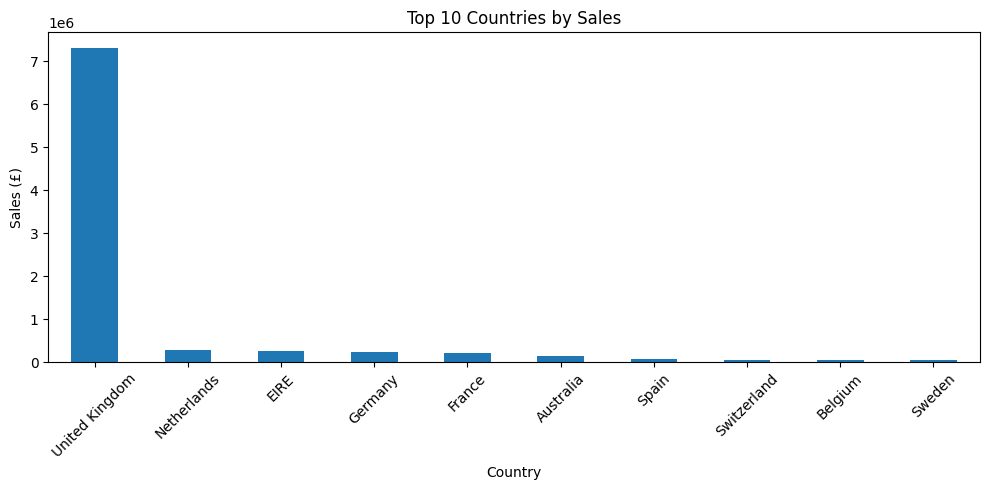

In [ ]:
import matplotlib.pyplot as plt

country_sales = (
    df.groupby('Country')['Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

country_sales.plot(kind='bar', figsize=(10, 5))

plt.title('Top 10 Countries by Sales')
plt.xlabel('Country')
plt.ylabel('Sales (£)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Convert InvoiceDate into a date format
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Extract the month and year
df['Month'] = df['InvoiceDate'].dt.to_period('M')

print(df[['InvoiceDate', 'Month', 'Sales']].head())

          InvoiceDate    Month  Sales
0 2010-12-01 08:26:00  2010-12  15.30
1 2010-12-01 08:26:00  2010-12  20.34
2 2010-12-01 08:26:00  2010-12  22.00
3 2010-12-01 08:26:00  2010-12  20.34
4 2010-12-01 08:26:00  2010-12  20.34


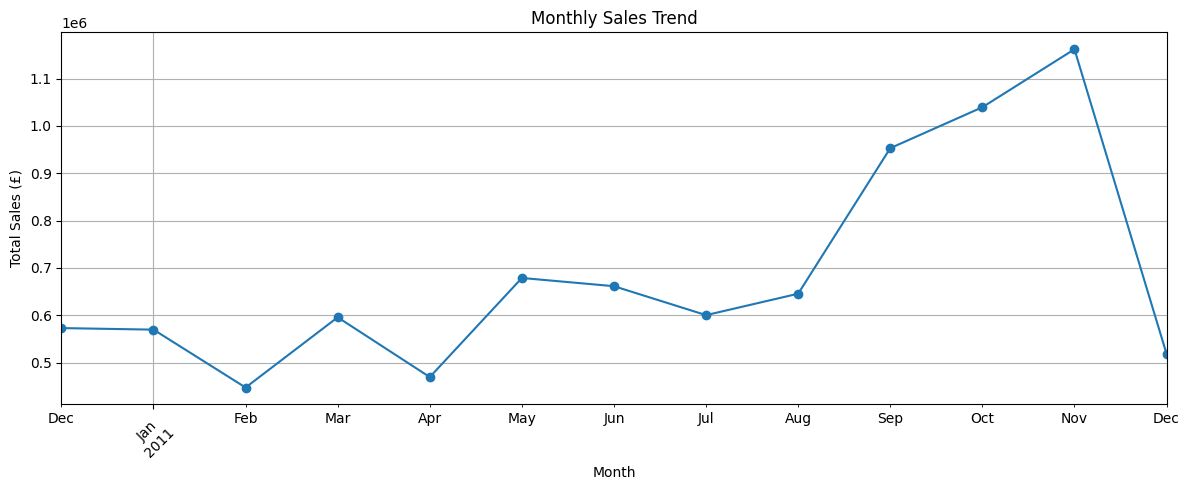

In [ ]:
import matplotlib.pyplot as plt

monthly_sales = df.groupby('Month')['Sales'].sum()

monthly_sales.plot(kind='line', figsize=(12, 5), marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales (£)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

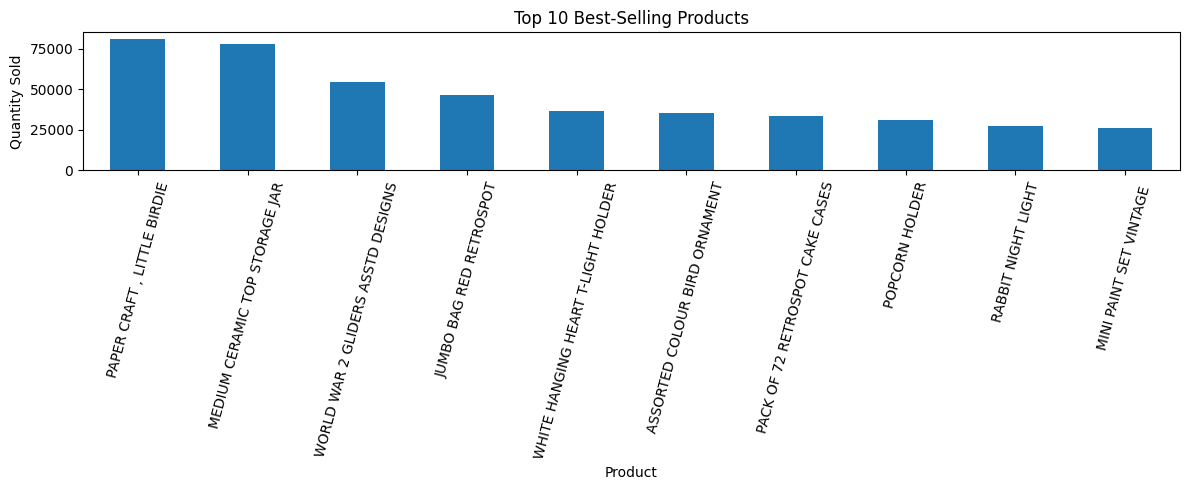

In [ ]:
top_products = (
    df.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products.plot(kind='bar', figsize=(12, 5))

plt.title('Top 10 Best-Selling Products')
plt.xlabel('Product')
plt.ylabel('Quantity Sold')
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [ ]:
# Calculate total sales for each customer
customer_sales = (
    df.groupby('CustomerID')['Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Customers by Sales:")
print(customer_sales)

Top 10 Customers by Sales:
CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194550.79
16446.0    168472.50
14911.0    143825.06
12415.0    124914.53
14156.0    117379.63
17511.0     91062.38
16029.0     81024.84
12346.0     77183.60
Name: Sales, dtype: float64


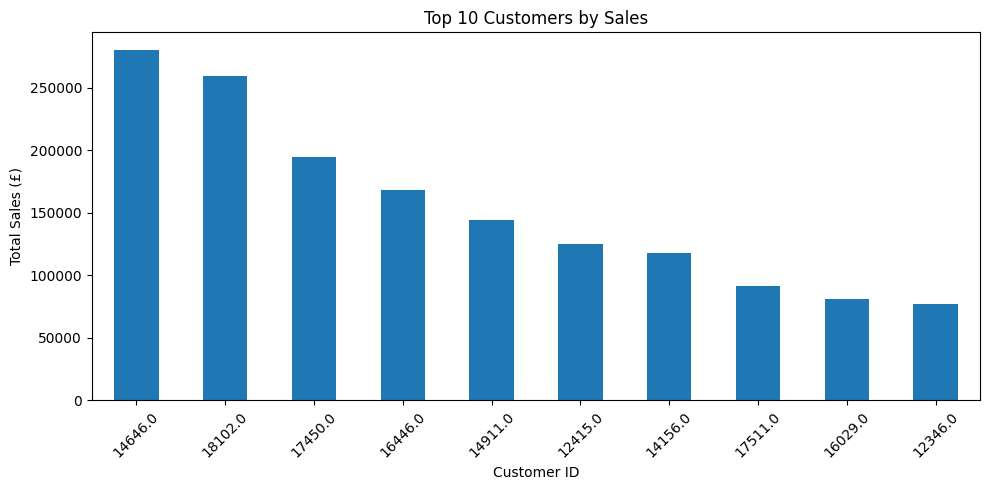

In [ ]:
import matplotlib.pyplot as plt

customer_sales.plot(kind='bar', figsize=(10, 5))

plt.title('Top 10 Customers by Sales')
plt.xlabel('Customer ID')
plt.ylabel('Total Sales (£)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Calculate important business metrics

total_sales = df['Sales'].sum()

total_orders = df['InvoiceNo'].nunique()

total_customers = df['CustomerID'].nunique()

total_products = df['StockCode'].nunique()

average_order_value = total_sales / total_orders if total_orders else 0

print("===== E-commerce Sales Analysis KPIs =====")
print("Total Sales: £", round(total_sales, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Unique Products:", total_products)
print("Average Order Value: £", round(average_order_value, 2))

===== E-commerce Sales Analysis KPIs =====
Total Sales: £ 8911407.9
Total Orders: 18532
Total Customers: 4338
Unique Products: 3665
Average Order Value: £ 480.87


In [ ]:
# Export cleaned data to a CSV file
df.to_csv('Online_Retail_Cleaned.csv', index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [ ]:
from google.colab import files

files.download('Online_Retail_Cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>